# Cookie Cats 游戏用户留存与 A/B Test 分析

## 1. 数据理解与探索

In [1]:
# 导入数据分析库
import pandas as pd

# 读取原始数据
df = pd.read_csv("cookie_cats.csv")

# 查看前5行
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.shape

(90189, 5)

## 2. 数据质量检查（Data Quality Check）

### 2.1 数据结构检查

In [5]:
# 查看数据的基本信息
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


### 2.2 检查缺失值和重复记录

In [41]:
# 1. 检查每个字段的缺失值
print("各字段缺失值数量：")
print(df.isnull().sum())

# 2. 检查完全重复的记录
print("\n完全重复的记录数量：")
print(df.duplicated().sum())

# 3. 检查玩家ID是否重复
print("\n重复玩家ID数量：")
print(df["userid"].duplicated().sum())

各字段缺失值数量：
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

完全重复的记录数量：
0

重复玩家ID数量：
0


### 2.3 检查实验分组是否正确

In [8]:
# 查看实验分组的种类
print(df["version"].unique())

# 统计每个实验组的人数
print(df["version"].value_counts())

['gate_30' 'gate_40']
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


In [9]:
# 检查是否存在未定义的实验分组
df["version"].isin(["gate_30", "gate_40"]).all()

True

### 2.4 检查游戏局数的分布和异常值

In [11]:
# 查看游戏局数的描述性统计
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

#### 平均游戏局数：51.87 中位游戏局数：16
#### 平均值显著高于中位数，说明分布可能明显右偏，少数游戏局数特别高的玩家会拉高平均值。

In [12]:
# 查看游戏局数最高的5条记录
df.nlargest(5, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


#### 第一名与第二名的差异非常大。先不要把49,854局的玩家删除
#### 因为这个数字可能是异常记录，也可能是真实的超高活跃用户。

### 2.5 验证游戏局数是否存在负值

In [13]:
# 检查游戏局数为负数的记录
(df["sum_gamerounds"] < 0).sum()

0

### 2.6 数据质量检查总结

本次分析的数据集共包含90,189名玩家和5个字段。

1. 完整性：各字段均不存在缺失值。
2. 唯一性：不存在重复玩家ID或完全重复的记录。
3. 分组检查：仅包含gate_30和gate_40两个实验组，
   玩家数量分别为44,700和45,489。
4. 合理性：游戏局数不存在负值。
5. 异常值：游戏局数最大值为49,854，
   远高于中位数16，需关注极端值对统计结果的影响。

初步结论：
数据整体完整，可以开展后续探索性分析。
对于游戏局数中的极端值，暂时保留原始记录，
后续通过敏感性分析评估其影响。

## 3. SQL 游戏数据分析
### 3.1 创建数据库与导入数据

In [15]:
import sqlite3
import pandas as pd

# 创建内存数据库
conn = sqlite3.connect(":memory:")

# 复制原始数据，避免修改 df
df_sql = df.copy()

# 将布尔值转化为 0 和 1
df_sql["retention_1"] = df_sql["retention_1"].astype(int)
df_sql["retention_7"] = df_sql["retention_7"].astype(int)

# 将数据导入 SQLite
df_sql.to_sql(
    "cookie_cats",
    conn,
    if_exists="replace",
    index=False
)

print("数据导入成功！")

数据导入成功！


In [16]:
sql = """
SELECT *
FROM cookie_cats
LIMIT 5;
"""

pd.read_sql_query(sql, conn)

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,0,0
1,337,gate_30,38,1,0
2,377,gate_40,165,1,0
3,483,gate_40,1,0,0
4,488,gate_40,179,1,1


### 3.2 使用 GROUP BY 统计实验组人数

In [17]:
sql = """
SELECT
    version,
    COUNT(*) AS player_count
FROM cookie_cats
GROUP BY version;
"""

pd.read_sql_query(sql, conn)

,version,player_count
0,gate_30,44700
1,gate_40,45489


### 3.3 使用 AVG 计算平均游戏局数

In [18]:
sql = """
SELECT
    version,
    COUNT(*) AS player_count,
    ROUND(AVG(sum_gamerounds), 2) AS avg_rounds
FROM cookie_cats
GROUP BY version;
"""

pd.read_sql_query(sql, conn)

,version,player_count,avg_rounds
0,gate_30,44700,52.46
1,gate_40,45489,51.30


### 3.4 用 SQL 计算次日留存率和7日留存率

In [20]:
sql = """
SELECT
    version,
    COUNT(*) AS player_count,

    SUM(retention_1) AS retained_day1,
    SUM(retention_7) AS retained_day7,

    ROUND(AVG(retention_1) * 100, 2) AS retention_1_pct,
    ROUND(AVG(retention_7) * 100, 2) AS retention_7_pct

FROM cookie_cats
GROUP BY version
ORDER BY version;
"""

retention_summary = pd.read_sql_query(sql, conn)

retention_summary

,version,player_count,retained_day1,retained_day7,retention_1_pct,retention_7_pct
0,gate_30,44700,20034,8502,44.82,19.02
1,gate_40,45489,20119,8279,44.23,18.20


### 3.5 分析玩家活跃度

In [21]:
sql = """
SELECT
    CASE
        WHEN sum_gamerounds <= 5 THEN '01_0-5局'
        WHEN sum_gamerounds <= 16 THEN '02_6-16局'
        WHEN sum_gamerounds <= 51 THEN '03_17-51局'
        ELSE '04_52局以上'
    END AS activity_group,

    COUNT(*) AS player_count,

    ROUND(AVG(retention_1) * 100, 2) AS retention_1_pct,
    ROUND(AVG(retention_7) * 100, 2) AS retention_7_pct

FROM cookie_cats
GROUP BY activity_group
ORDER BY activity_group;
"""

pd.read_sql_query(sql, conn)

,activity_group,player_count,retention_1_pct,retention_7_pct
0,01_0-5局,24717,6.82,1.27
1,02_6-16局,20397,27.44,4.13
2,03_17-51局,22622,60.18,14.01
3,04_52局以上,22453,85.76,55.47


### 3.6 使用 CTE 整理分析结果

In [22]:
sql = """
WITH group_stats AS (
    SELECT
        version,
        COUNT(*) AS player_count,
        ROUND(AVG(sum_gamerounds), 2) AS avg_rounds,
        ROUND(AVG(retention_1) * 100, 2) AS retention_1_pct,
        ROUND(AVG(retention_7) * 100, 2) AS retention_7_pct
    FROM cookie_cats
    GROUP BY version
)

SELECT *
FROM group_stats
ORDER BY version;
"""

pd.read_sql_query(sql, conn)

,version,player_count,avg_rounds,retention_1_pct,retention_7_pct
0,gate_30,44700,52.46,44.82,19.02
1,gate_40,45489,51.30,44.23,18.20


### 3.7 SQL分析总结

本阶段使用 SQLite 对 Cookie Cats 玩家数据进行了分组统计和留存分析。

主要完成：
1. 使用 SELECT 查询玩家数据。
2. 使用 GROUP BY 和 COUNT 计算实验组样本量。
3. 使用 AVG 计算平均游戏局数。
4. 使用 SUM 和 AVG 计算次日、7日留存指标。
5. 使用 CASE WHEN 进行玩家游戏局数分层。
6. 使用 CTE 整理实验组统计结果。

初步发现：
Gate 30组的次日和7日留存率均略高于Gate 40组。
但目前尚未进行显著性检验，不能直接断定关卡调整具有真实的留存影响。

后续计划：
开展玩家行为分布分析及A/B实验统计检验。

## 4. 玩家行为与留存探索性分析

### 4.1 玩家行为指标汇总

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 创建图表和分析结果保存文件夹
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# 按实验组汇总核心指标
summary = df.groupby("version").agg(
    player_count=("userid", "count"),
    avg_rounds=("sum_gamerounds", "mean"),
    median_rounds=("sum_gamerounds", "median"),
    p95_rounds=("sum_gamerounds", lambda x: x.quantile(0.95)),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean")
)

# 将留存率转换成百分数
summary["retention_1"] *= 100
summary["retention_7"] *= 100

summary.round(2)

,player_count,avg_rounds,median_rounds,p95_rounds,retention_1,retention_7
version,,,,,,
gate_30,44700,52.46,17.0,222.0,44.82,19.02
gate_40,45489,51.30,16.0,220.0,44.23,18.20


### 4.2 分析玩家游戏局数的分布

99%分位数： 493.0


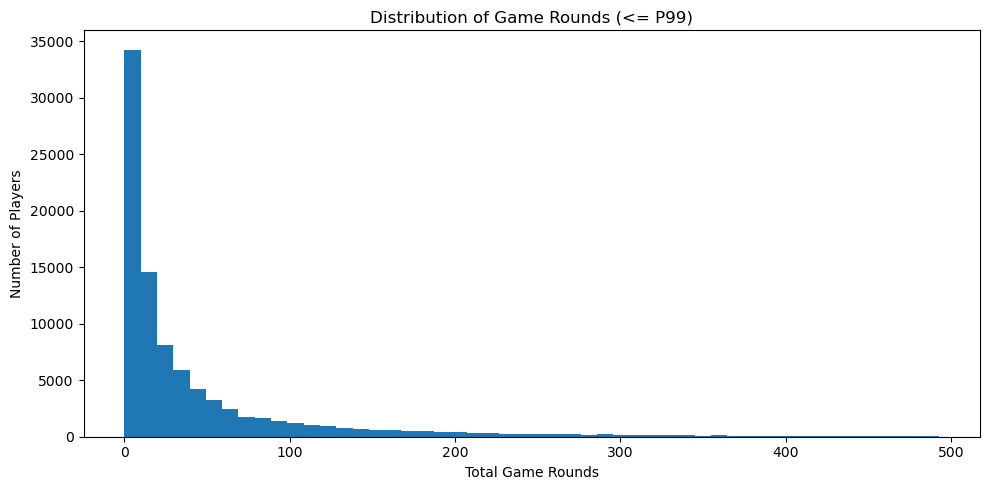

In [25]:
# 计算99%分位数
p99 = df["sum_gamerounds"].quantile(0.99)

print("99%分位数：", p99)

# 只截取99%分位数以内的数据用于绘图
rounds_plot = df.loc[
    df["sum_gamerounds"] <= p99,
    "sum_gamerounds"
]

# 创建图表
plt.figure(figsize=(10, 5))

plt.hist(rounds_plot, bins=50)

plt.title("Distribution of Game Rounds (<= P99)")
plt.xlabel("Total Game Rounds")
plt.ylabel("Number of Players")

plt.tight_layout()

# 保存图表
plt.savefig(output_dir / "01_rounds_distribution.png", dpi=300)

plt.show()

### 4.3 对比两组玩家的游戏局数

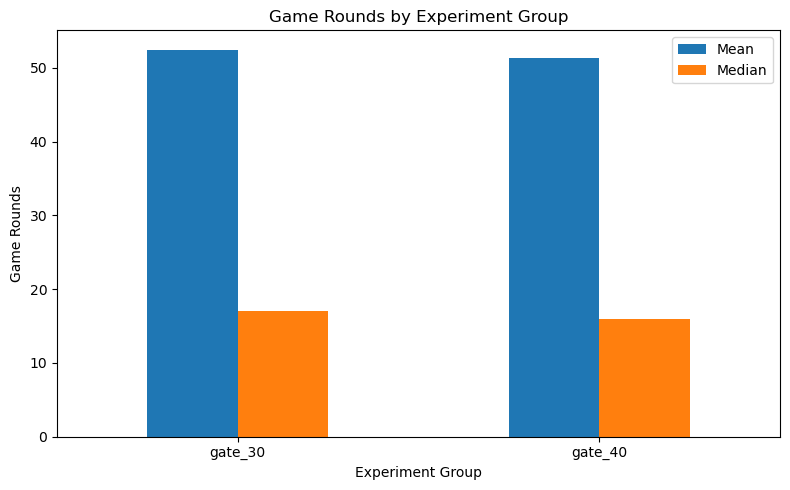

In [26]:
# 提取比较指标
rounds_compare = summary[
    ["avg_rounds", "median_rounds"]
]

# 绘制分组柱状图
ax = rounds_compare.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Game Rounds by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Game Rounds")

plt.legend(["Mean", "Median"])

plt.tight_layout()
plt.savefig(output_dir / "02_group_rounds_comparison.png", dpi=300)
plt.show()

### 敏感性分析

In [27]:
# 找出游戏局数最大的玩家
max_index = df["sum_gamerounds"].idxmax()

# 暂时排除这一条记录
df_without_max = df.drop(index=max_index)

# 比较两组平均游戏局数
print("原始平均值：")
print(df.groupby("version")["sum_gamerounds"].mean())

print("\n排除最大值后的平均值：")
print(df_without_max.groupby("version")["sum_gamerounds"].mean())

原始平均值：
version
gate_30    52.456264
gate_40    51.298776
Name: sum_gamerounds, dtype: float64

排除最大值后的平均值：
version
gate_30    51.342111
gate_40    51.298776
Name: sum_gamerounds, dtype: float64


#### 这说明Gate 30的平均游戏局数优势，在很大程度上受到单个极端值影响。

### 4.4 对比次日与第7日留存率

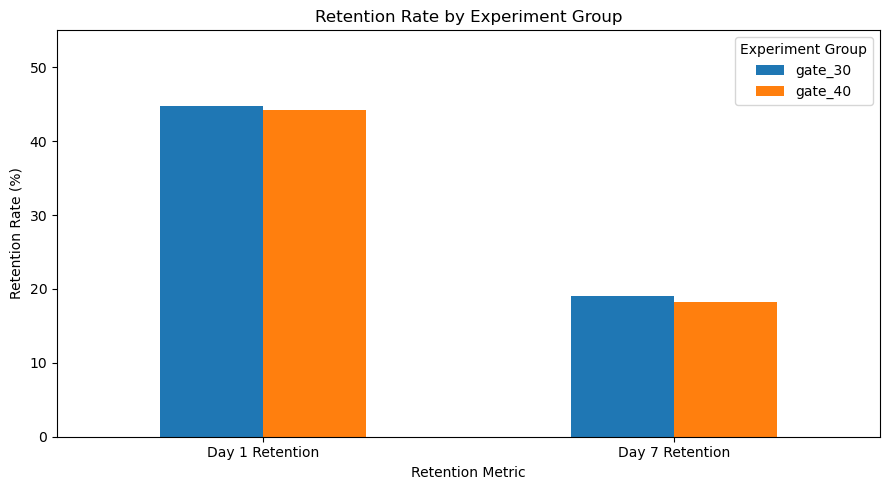

In [28]:
# 提取两组留存率
retention_compare = summary[
    ["retention_1", "retention_7"]
].T

# 绘制分组柱状图
ax = retention_compare.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Retention Rate by Experiment Group")
plt.xlabel("Retention Metric")
plt.ylabel("Retention Rate (%)")

plt.xticks(
    ticks=[0, 1],
    labels=["Day 1 Retention", "Day 7 Retention"]
)

plt.ylim(0, 55)
plt.legend(title="Experiment Group")

plt.tight_layout()
plt.savefig(output_dir / "03_retention_comparison.png", dpi=300)
plt.show()

In [29]:
day1_diff = (
    summary.loc["gate_30", "retention_1"]
    - summary.loc["gate_40", "retention_1"]
)

day7_diff = (
    summary.loc["gate_30", "retention_7"]
    - summary.loc["gate_40", "retention_7"]
)

print(f"次日留存率差异：{day1_diff:.2f} 个百分点")
print(f"第7日留存率差异：{day7_diff:.2f} 个百分点")

次日留存率差异：0.59 个百分点
第7日留存率差异：0.82 个百分点


### 4.5 进一步分析：不同游戏局数玩家的留存情况

In [30]:
# 创建副本，避免直接修改原始数据
df_segment = df.copy()

# 按游戏局数区间划分玩家
df_segment["activity_group"] = pd.cut(
    df_segment["sum_gamerounds"],
    bins=[-1, 5, 16, 51, np.inf],
    labels=["0-5", "6-16", "17-51", "52+"]
)

# 计算不同分层的玩家数量和留存率
segment_summary = df_segment.groupby(
    "activity_group",
    observed=True
).agg(
    player_count=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean")
)

segment_summary["retention_1"] *= 100
segment_summary["retention_7"] *= 100

segment_summary.round(2)

,player_count,retention_1,retention_7
activity_group,,,
0-5,24717,6.82,1.27
6-16,20397,27.44,4.13
17-51,22622,60.18,14.01
52+,22453,85.76,55.47


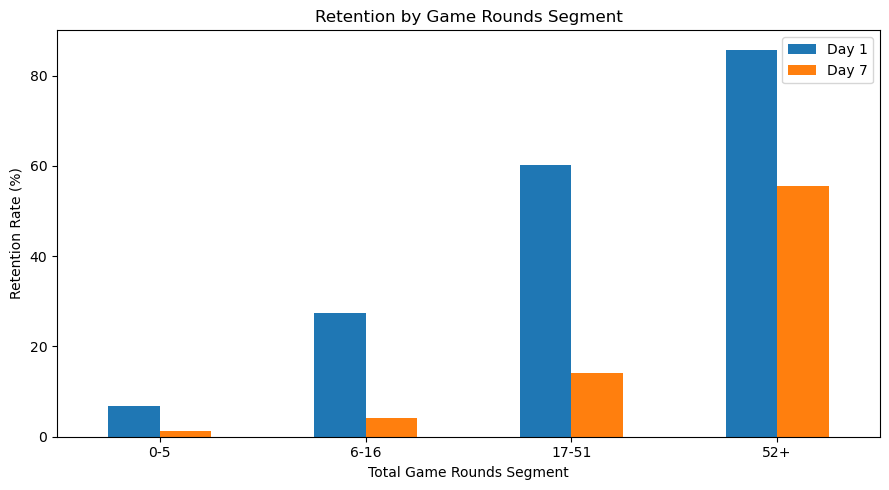

In [31]:
segment_summary[
    ["retention_1", "retention_7"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Retention by Game Rounds Segment")
plt.xlabel("Total Game Rounds Segment")
plt.ylabel("Retention Rate (%)")

plt.legend(["Day 1", "Day 7"])

plt.tight_layout()
plt.savefig(output_dir / "04_segment_retention.png", dpi=300)
plt.show()

### 4.6 保存本阶段的数据分析成果

In [33]:
# 保存实验组指标汇总表
summary.to_csv(
    output_dir / "group_metrics.csv",
    encoding="utf-8-sig"
)

# 保存玩家分层指标汇总表
segment_summary.to_csv(
    output_dir / "segment_metrics.csv",
    encoding="utf-8-sig"
)

print("分析结果保存完成！")

分析结果保存完成！


### 第4阶段：玩家行为与留存分析结论

**1. 玩家行为分布**

Cookie Cats 玩家游戏局数呈明显右偏分布，整体平均游戏局数约51.87局，中位数为16局，99%分位数为493局。少数玩家的极高游戏局数明显影响了平均值，因此分析玩家活跃程度时需要同时参考中位数及分位数。

**2. 实验组活跃度对比**

Gate 30组的平均游戏局数为52.46局，Gate 40组为51.30局。但敏感性分析发现，排除单条最高游戏局数记录后，两组平均值分别约为51.34局和51.30局，表明原始平均值差异受到极端值的较大影响。

**3. 实验组留存表现**

Gate 30组的次日留存率为44.82%，第7日留存率为19.02%；Gate 40组分别为44.23%和18.20%。Gate 30组分别高出约0.59和0.82个百分点，但尚需通过统计检验判断差异是否显著。

**4. 玩家行为分层**

按游戏局数进行事后分层发现，局数较高的玩家通常具有较高留存率。但该分析只反映关联关系，不能据此认定增加游戏局数能够直接改善留存。

**5. 后续研究方向**

下一阶段将对实验组样本比例、次日和第7日留存率差异进行统计检验，并计算置信区间，为是否调整关卡机制提供更可靠的决策依据。

## 5. A/B Test 实验分析

### 5.1 实验目标与假设

业务目标：
评估将游戏 Gate 从第30关调整到第40关，
是否会改变玩家的次日与第7日留存率。

对照组 A：gate_30
实验组 B：gate_40

本次练习以第7日留存率为主要分析指标，
次日留存率为辅助指标。

显著性水平：α = 0.05
检验方法：双侧两比例 Z 检验

### 5.2 SRM检验：先检查实验分流

In [34]:
import numpy as np
import pandas as pd
from scipy.stats import chisquare

# 统计实际实验组人数
observed = df["version"].value_counts().reindex(
    ["gate_30", "gate_40"]
)

# 假设原始实验计划为50:50分流
expected = np.array([len(df) / 2, len(df) / 2])

# 卡方拟合优度检验
chi2_stat, srm_p = chisquare(
    f_obs=observed.values,
    f_exp=expected
)

print("实际分组人数：")
print(observed)

print(f"\n卡方统计量：{chi2_stat:.4f}")
print(f"SRM P值：{srm_p:.6f}")

实际分组人数：
version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

卡方统计量：6.9024
SRM P值：0.008608


#### H₀：实验实际分流符合预期的50:50比例。H₁：实际分流比例偏离了预期比例。
#### 设置SRM预警阈值0.01，p值<0.01 在1%的显著性水平下，可以拒绝原假设 H₀
#### 在假设实验预期分流比例为1:1的情况下，发现值得进一步核查的样本比例差异，需确认分流配置、日志采集及样本筛选过程。

### 5.3 两比例Z检验：留存率差异显著吗？

In [35]:
#第7日留存率Z检验
from scipy.stats import norm

# 两组数据
a = df[df["version"] == "gate_30"]
b = df[df["version"] == "gate_40"]

# 样本量
n_a = len(a)
n_b = len(b)

# 第7日留存人数
x_a = a["retention_7"].sum()
x_b = b["retention_7"].sum()

# 各组留存率
p_a = x_a / n_a
p_b = x_b / n_b

# 合并留存率（H0成立时）
p_pool = (x_a + x_b) / (n_a + n_b)

# 合并标准误
se_pool = np.sqrt(
    p_pool * (1 - p_pool) * (1/n_a + 1/n_b)
)

# Z统计量
z_stat = (p_b - p_a) / se_pool

# 双侧P值
p_value = 2 * norm.sf(abs(z_stat))

print(f"Gate 30留存率：{p_a:.4%}")
print(f"Gate 40留存率：{p_b:.4%}")
print(f"Z统计量：{z_stat:.4f}")
print(f"P值：{p_value:.6f}")

Gate 30留存率：19.0201%
Gate 40留存率：18.2000%
Z统计量：-3.1644
P值：0.001554


In [36]:
def two_proportion_ztest(df, metric):
    a = df.loc[df["version"] == "gate_30", metric]
    b = df.loc[df["version"] == "gate_40", metric]

    n_a, n_b = len(a), len(b)
    x_a, x_b = int(a.sum()), int(b.sum())

    p_a = x_a / n_a
    p_b = x_b / n_b

    p_pool = (x_a + x_b) / (n_a + n_b)

    se = np.sqrt(
        p_pool * (1 - p_pool) * (1/n_a + 1/n_b)
    )

    z = (p_b - p_a) / se
    p = 2 * norm.sf(abs(z))

    return {
        "metric": metric,
        "gate30_rate": p_a,
        "gate40_rate": p_b,
        "diff": p_b - p_a,
        "z": z,
        "p_value": p
    }

results = pd.DataFrame([
    two_proportion_ztest(df, "retention_1"),
    two_proportion_ztest(df, "retention_7")
])

results.round(6)

,metric,gate30_rate,gate40_rate,diff,z,p_value
0,retention_1,0.448188,0.442283,-0.005905,-1.784086,0.074410
1,retention_7,0.190201,0.182000,-0.008201,-3.164359,0.001554


#### 在常规两比例Z检验的假设下，第7日留存有统计显著差异（p值<0.05 且整个区间都在0点左边，差异方向为负，说明Gate40留存率小于Gate30），而次日留存的证据（p值>0.05 且区间跨过了0点）不足以拒绝原假设。

### 5.5 计算95%置信区间

In [37]:
# 95%置信区间的临界值
z_critical = norm.ppf(0.975)

def retention_ci(df, metric):
    a = df.loc[df["version"] == "gate_30", metric]
    b = df.loc[df["version"] == "gate_40", metric]

    p_a, p_b = a.mean(), b.mean()
    n_a, n_b = len(a), len(b)

    diff = p_b - p_a

    # 不合并标准误
    se = np.sqrt(
        p_a * (1-p_a) / n_a +
        p_b * (1-p_b) / n_b
    )

    lower = diff - z_critical * se
    upper = diff + z_critical * se

    return lower, upper

results[["ci_lower", "ci_upper"]] = pd.DataFrame(
    [
        retention_ci(df, metric)
        for metric in results["metric"]
    ],
    index=results.index
)

# 转换为百分点便于展示
ci_table = results[
    ["metric", "diff", "ci_lower", "ci_upper", "p_value"]
].copy()

for col in ["diff", "ci_lower", "ci_upper"]:
    ci_table[col] *= 100

ci_table.round(4)

,metric,diff,ci_lower,ci_upper,p_value
0,retention_1,-0.5905,-1.2392,0.0582,0.0744
1,retention_7,-0.8201,-1.3282,-0.3121,0.0016


#### 次日留存： 区间包含0，所以在5%双侧检验下不显著。
#### 第7日留存： 整个区间位于0以下，说明在相关统计假设成立时，数据支持Gate 40的第7日留存率低于Gate 30。

### 5.6 转化为业务决策：应该把 Gate 移到40关吗？

#### 本次实验对比了第30关和第40关设置进度限制对玩家留存的影响。
#### 从样本结果看，Gate 40的次日留存率下降约0.59个百分点，差异未达到5%统计显著水平；第7日留存率下降约0.82个百分点，双侧Z检验P值约0.00155，显示出不利于长期留存的信号。
#### 同时，在假设预期分流比例为1:1的情况下，SRM检验结果提示需要核查实验分流及数据采集情况。
#### 现阶段不建议直接全面上线Gate 40。 建议先确认实验配置和数据完整性，并结合玩家到达Gate的比例、收入、关卡完成情况等更多指标进行综合评估。
#### 如果实验质量核查通过且留存下降的结果依然稳健，则建议优先保留Gate 30或重新设计关卡限制方案。

In [38]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# 添加显著性判断
results["significant_05"] = results["p_value"] < 0.05

# 保存完整统计结果
results.to_csv(
    output_dir / "ab_test_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("A/B Test分析结果已保存！")

A/B Test分析结果已保存！


,metric,diff_pp,lower_pp,upper_pp
0,次日留存,-0.591,-1.239,0.058
1,第7日留存,-0.820,-1.328,-0.312


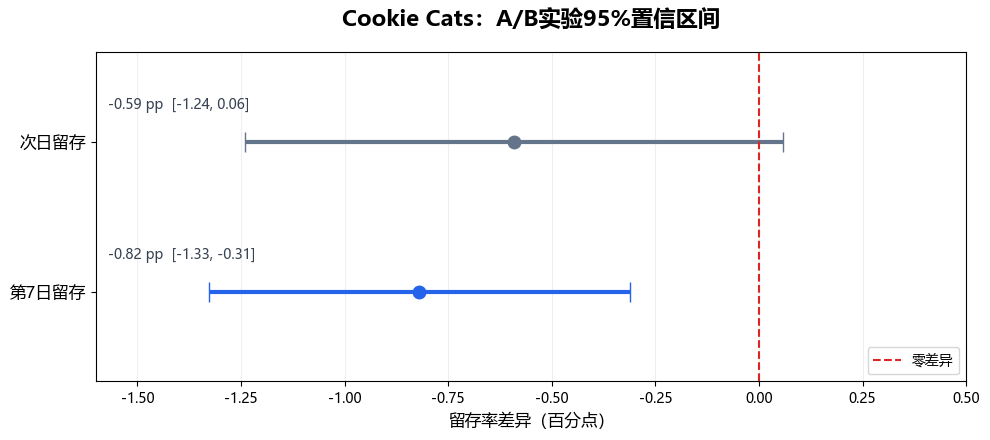

图片保存成功：outputs/CookieCats_95CI.png


In [40]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from pathlib import Path

# 1. 读取原始数据
df = pd.read_csv("cookie_cats.csv")

# 2. 设置中文字体
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 3. 计算两个留存指标的95%置信区间
results_ci = []

for metric, label in [
    ("retention_1", "次日留存"),
    ("retention_7", "第7日留存")
]:
    a = df.loc[df["version"] == "gate_30", metric]
    b = df.loc[df["version"] == "gate_40", metric]

    p_a = a.mean()
    p_b = b.mean()

    # 实验组 - 对照组
    diff = p_b - p_a

    # 非合并标准误
    se = np.sqrt(
        p_a * (1 - p_a) / len(a) +
        p_b * (1 - p_b) / len(b)
    )

    # 95%置信区间
    lower = diff - norm.ppf(0.975) * se
    upper = diff + norm.ppf(0.975) * se

    results_ci.append({
        "metric": label,
        "diff_pp": diff * 100,
        "lower_pp": lower * 100,
        "upper_pp": upper * 100
    })

ci_df = pd.DataFrame(results_ci)
display(ci_df.round(3))

# 4. 创建绘图区域
fig, ax = plt.subplots(figsize=(10, 4.5))

colors = ["#64748B", "#2563EB"]

# 5. 逐行绘制置信区间
for y, row in ci_df.iterrows():

    diff = row["diff_pp"]
    lower = row["lower_pp"]
    upper = row["upper_pp"]

    ax.errorbar(
        x=diff,
        y=y,
        xerr=[[diff - lower], [upper - diff]],
        fmt="o",
        color=colors[y],
        markersize=9,
        capsize=7,
        linewidth=3
    )

# 6. 添加零差异参考线
ax.axvline(
    x=0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label="零差异"
)

# 7. 设置图表样式
ax.set_yticks([0, 1])
ax.set_yticklabels(ci_df["metric"], fontsize=12)
ax.invert_yaxis()

ax.set_xlim(-1.6, 0.5)
ax.set_ylim(1.6, -0.6)

ax.set_xlabel("留存率差异（百分点）", fontsize=12)
ax.set_title(
    "Cookie Cats：A/B实验95%置信区间",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.grid(axis="x", alpha=0.2)
ax.legend(loc="lower right")

# 8. 添加数值标签
for y, row in ci_df.iterrows():
    label = (
        f'{row["diff_pp"]:+.2f} pp  '
        f'[{row["lower_pp"]:.2f}, '
        f'{row["upper_pp"]:.2f}]'
    )
    ax.text(
        -1.57, y - 0.22,
        label,
        fontsize=10,
        color="#374151"
    )

plt.tight_layout()

# 9. 保存PNG图片
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

plt.savefig(
    output_dir / "CookieCats_95CI.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("图片保存成功：outputs/CookieCats_95CI.png")
